# Palmer Penguins: linear regression in Python

Python notebook equivalent of `00_sample_analysis.R`, based on the University of Twente research-software template.

**Research question:** How is penguin body mass associated with bill length across all species?

**Data provenance:** [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) (Gorman et al., 2014), loaded from the Python `palmerpenguins` package. The dataset is included with the package; the notebook does not download a CSV at runtime.

**Execution:** Open this notebook from the repository `code/` folder and run all cells from top to bottom. The notebook also works when the working directory is the repository root. Outputs are written relative to the repository root, not the notebook's current working directory.

## 1. Setup & dependencies

Install dependencies from the repository root with `python -m pip install -r requirements.txt`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from palmerpenguins import load_penguins

# Support running cells from either the repository root or its code/ directory.
working_dir = Path.cwd()
if (working_dir / "code").is_dir() and (working_dir / "README.md").is_file():
    project_root = working_dir
elif working_dir.name == "code" and (working_dir.parent / "README.md").is_file():
    project_root = working_dir.parent
else:
    raise FileNotFoundError(
        "Run the notebook with the working directory set to the repository root or code/ folder."
    )

processed_dir = project_root / "data" / "processed"
reports_dir = project_root / "outputs" / "reports"
figures_dir = project_root / "outputs" / "figures"
for folder in (processed_dir, reports_dir, figures_dir):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")

Project root: c:\Users\KikkertID1\Documents\my_research_project


## 2. Data loading & provenance

Load the original dataset, then remove rows with missing bill length or body mass. We deliberately retain rows with missing values in other columns, matching the R script.

In [2]:
penguins = load_penguins()
processed_data = penguins.dropna(subset=["bill_length_mm", "body_mass_g"]).copy()

processed_data.to_csv(processed_dir / "cleaned_penguins.csv", index=False)
print(f"Rows before cleaning: {len(penguins)}")
print(f"Rows after cleaning: {len(processed_data)}")
processed_data.head()

Rows before cleaning: 344
Rows after cleaning: 342


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


## 3. Analysis: linear regression

Fit an ordinary least squares (OLS) regression: `body_mass_g ~ bill_length_mm`. As in the original R analysis, species is **not** a model predictor; it is only used to distinguish points in the graph.

In [3]:
penguin_model = smf.ols("body_mass_g ~ bill_length_mm", data=processed_data).fit()
model_summary = penguin_model.summary().as_text()
(reports_dir / "regression_results.txt").write_text(model_summary + "\n", encoding="utf-8")
print(model_summary)

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.354
Model:                            OLS   Adj. R-squared:                  0.352
Method:                 Least Squares   F-statistic:                     186.4
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           3.81e-34
Time:                        14:04:12   Log-Likelihood:                -2697.0
No. Observations:                 342   AIC:                             5398.
Df Residuals:                     340   BIC:                             5406.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        362.3067    283.345      1.

## 4. Visualization

Show individual penguins by species, an overall OLS line and the **95% confidence interval for the mean prediction** (not a prediction interval).

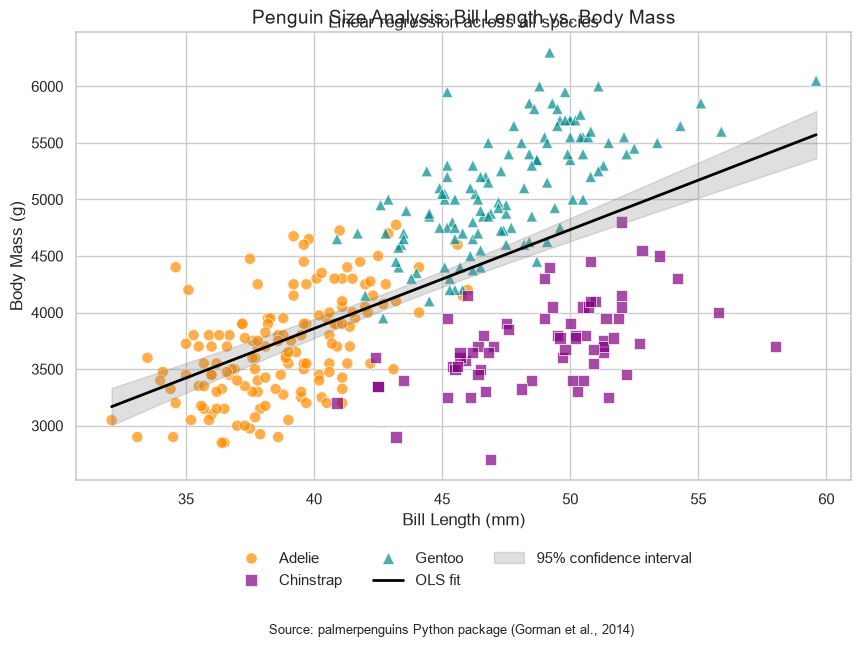

In [4]:
species_palette = {"Adelie": "darkorange", "Chinstrap": "purple", "Gentoo": "darkcyan"}
species_markers = {"Adelie": "o", "Chinstrap": "s", "Gentoo": "^"}

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=processed_data,
    x="bill_length_mm",
    y="body_mass_g",
    hue="species",
    style="species",
    hue_order=list(species_palette),
    style_order=list(species_markers),
    palette=species_palette,
    markers=species_markers,
    alpha=0.7,
    s=65,
    ax=ax,
)

x_grid = np.linspace(processed_data["bill_length_mm"].min(), processed_data["bill_length_mm"].max(), 200)
predictions = penguin_model.get_prediction(pd.DataFrame({"bill_length_mm": x_grid})).summary_frame(alpha=0.05)
ax.plot(x_grid, predictions["mean"].to_numpy(), color="black", linewidth=2, label="OLS fit")
ax.fill_between(
    x_grid,
    predictions["mean_ci_lower"].to_numpy(),
    predictions["mean_ci_upper"].to_numpy(),
    color="gray", alpha=0.25, label="95% confidence interval",
)

ax.set_title("Penguin Size Analysis: Bill Length vs. Body Mass", fontsize=14)
ax.text(0.5, 1.01, "Linear regression across all species", transform=ax.transAxes, ha="center")
ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Body Mass (g)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
fig.text(0.5, 0.01, "Source: palmerpenguins Python package (Gorman et al., 2014)", ha="center", fontsize=9)
fig.subplots_adjust(bottom=0.23, top=0.87)
plt.show()

## 5. FAIR export

Export a PNG for sharing and a vector PDF for publication. The cleaned dataset and the regression report were saved in the earlier steps.

In [5]:
figure_basename = figures_dir / "fig-01-penguin-regression"
fig.savefig(figure_basename.with_suffix(".png"), dpi=300)
fig.savefig(figure_basename.with_suffix(".pdf"))

print("Success: cleaned dataset, statistical report and PNG/PDF figures generated.")
print(f"Data: {processed_dir / 'cleaned_penguins.csv'}")
print(f"Report: {reports_dir / 'regression_results.txt'}")
print(f"Figures: {figure_basename}.png / .pdf")

Success: cleaned dataset, statistical report and PNG/PDF figures generated.
Data: c:\Users\KikkertID1\Documents\my_research_project\data\processed\cleaned_penguins.csv
Report: c:\Users\KikkertID1\Documents\my_research_project\outputs\reports\regression_results.txt
Figures: c:\Users\KikkertID1\Documents\my_research_project\outputs\figures\fig-01-penguin-regression.png / .pdf


### Reproducibility notes

- Model: ordinary least squares with an intercept, matching R `lm(body_mass_g ~ bill_length_mm)`.
- No random sampling is used, so no random seed is needed.
- The notebook creates output folders if missing; generated files should normally be excluded from Git via `.gitignore`.
- To recreate the same software environment, capture the Python and package versions in a `requirements.txt` or a lockfile
- R and Python statistical output formatting may differ slightly although the fitted regression is mathematically equivalent.